In [1]:
# Create cortical and subcortical masks using the Harvard-Oxford atlas
# Fetch atlas, then create one bilateral mask per region
# Then also resample to our beta maps and save the masks

In [2]:
from nilearn.datasets import fetch_atlas_harvard_oxford
import nibabel as nib
import numpy as np
import pandas as pd
from pathlib import Path
from nilearn.image import resample_to_img
import os
import json
import subprocess
from nilearn.image import load_img
from nilearn.plotting import plot_roi
from templateflow import api as tf
from nilearn.datasets import fetch_atlas_harvard_oxford
from nilearn.image import resample_to_img
import nibabel as nib, numpy as np

In [3]:
config = json.load(open("../../config.json"))

reference_img_path = f"{config['data_dir']}/ds003242-1.0.0/derivatives/first_level_nipype/sub-SAXSISO01b/CIC/model/run1/con_1_food_gt_control_cope.nii.gz"
output_dir = "../../masks_MNI152NLin2009cAsym"

In [4]:
# def tf_ho(atlas, thr="th0"):
#     return nib.load(str(tf.get("MNI152NLin2009cAsym", atlas=atlas, desc=thr,
#                                suffix="dseg", resolution=2, extension="nii.gz")))

# cort_img = tf_ho("HOCPA")      # bilateral cortical, 2009c
# sub_img  = tf_ho("HOSPA")      # subcortical, 2009c
# cort_labels = fetch_atlas_harvard_oxford("cort-maxprob-thr0-2mm").labels   # same index order
# sub_labels  = fetch_atlas_harvard_oxford("sub-maxprob-thr0-2mm").labels

# Cortical and subcortical regions

In [5]:
def tf_ho(atlas, thr="th25"):
    return nib.load(str(tf.get("MNI152NLin2009cAsym", atlas=atlas, desc=thr,
                                suffix="dseg", resolution=2, extension="nii.gz")))  

In [6]:
def make_roi_masks(reference_img, output_dir):

    os.makedirs(output_dir, exist_ok=True)

    # Load reference image
    if isinstance(reference_img, str):
        reference_img = nib.load(reference_img)

    # Fetch atlases
    cort_img = tf_ho("HOCPA")      # bilateral cortical, 2009c
    sub_img  = tf_ho("HOSPA")      # subcortical, 2009c
    cort_labels = fetch_atlas_harvard_oxford("cort-maxprob-thr25-2mm").labels   # same index order
    sub_labels  = fetch_atlas_harvard_oxford("sub-maxprob-thr25-2mm").labels

    cort_data = cort_img.get_fdata().astype(np.int16)
    sub_data = sub_img.get_fdata().astype(np.int16)

    # Every cortical label is already bilateral in this atlas.

    roi_definitions = {}
    for label_id, label in enumerate(cort_labels):
        if label == "Background":
            continue
        roi_definitions[label] = (cort_img, cort_data, [label_id])

    # Merge left and right subcortical labels under a single region name.
    sub_groups = {}
    for label_id, label in enumerate(sub_labels):
        if label == "Background":
            continue
        name = label.removeprefix("Left ").removeprefix("Right ")
        sub_groups.setdefault(name, []).append(label_id)

    for name, ids in sub_groups.items():
        if name in roi_definitions:
            raise ValueError(f"Duplicate ROI name across atlases: {name}")
        roi_definitions[name] = (sub_img, sub_data, ids)

    for roi_name, (source_img, data, ids) in roi_definitions.items():
        mask = np.isin(data, ids).astype(np.uint8)
        mask_img = nib.Nifti1Image(mask, source_img.affine)

        resampled = resample_to_img(mask_img, reference_img, interpolation="nearest")
        resampled_data = (resampled.get_fdata() > 0).astype(np.uint8)
        final_img = nib.Nifti1Image(resampled_data, reference_img.affine)

        out_path = os.path.join(output_dir, f"{roi_name}.nii.gz")
        final_img.to_filename(out_path)
        print(f"Saved: {out_path}")


In [7]:
make_roi_masks(reference_img_path,output_dir)

[fetch_atlas_harvard_oxford] Dataset found in /Users/anna/nilearn_data/fsl
[fetch_atlas_harvard_oxford] Dataset found in /Users/anna/nilearn_data/fsl
Saved: ../../masks_MNI152NLin2009cAsym/Frontal Pole.nii.gz
Saved: ../../masks_MNI152NLin2009cAsym/Insular Cortex.nii.gz
Saved: ../../masks_MNI152NLin2009cAsym/Superior Frontal Gyrus.nii.gz
Saved: ../../masks_MNI152NLin2009cAsym/Middle Frontal Gyrus.nii.gz
Saved: ../../masks_MNI152NLin2009cAsym/Inferior Frontal Gyrus, pars triangularis.nii.gz
Saved: ../../masks_MNI152NLin2009cAsym/Inferior Frontal Gyrus, pars opercularis.nii.gz
Saved: ../../masks_MNI152NLin2009cAsym/Precentral Gyrus.nii.gz
Saved: ../../masks_MNI152NLin2009cAsym/Temporal Pole.nii.gz
Saved: ../../masks_MNI152NLin2009cAsym/Superior Temporal Gyrus, anterior division.nii.gz
Saved: ../../masks_MNI152NLin2009cAsym/Superior Temporal Gyrus, posterior division.nii.gz
Saved: ../../masks_MNI152NLin2009cAsym/Middle Temporal Gyrus, anterior division.nii.gz
Saved: ../../masks_MNI152NLin2

Subcallosal Cortex.nii.gz
SNc_VTA.nii.gz
Cingulate Gyrus, anterior division.nii.gz
Caudate.nii.gz
Superior Frontal Gyrus.nii.gz
Temporal Fusiform Cortex, anterior division.nii.gz
HN.nii.gz
Superior Parietal Lobule.nii.gz
Insular Cortex.nii.gz
SNr.nii.gz


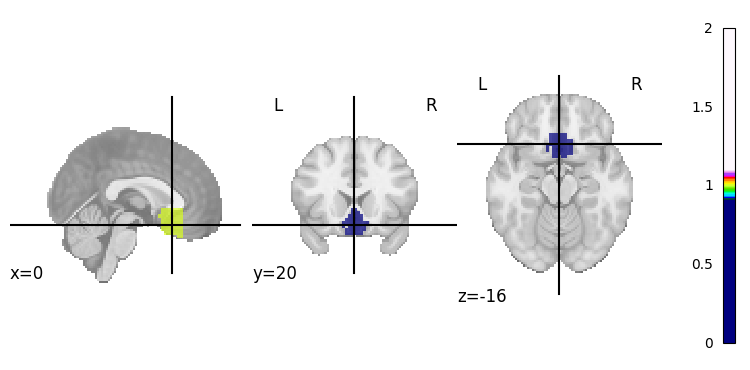

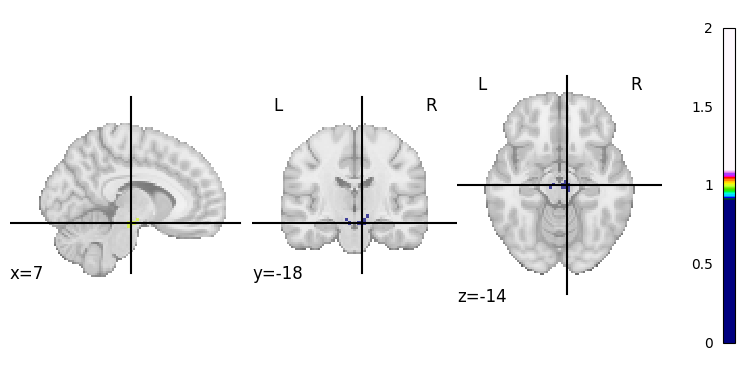

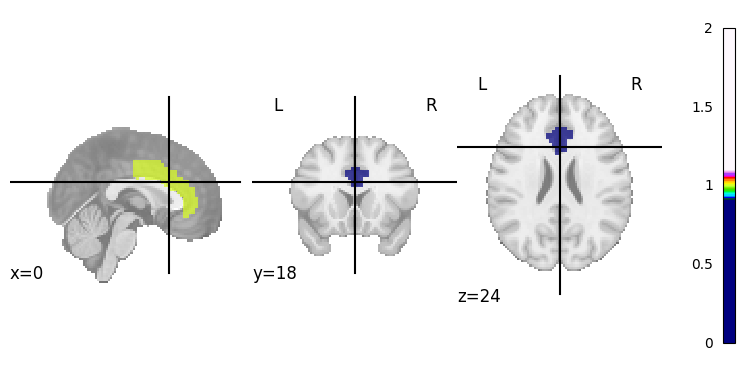

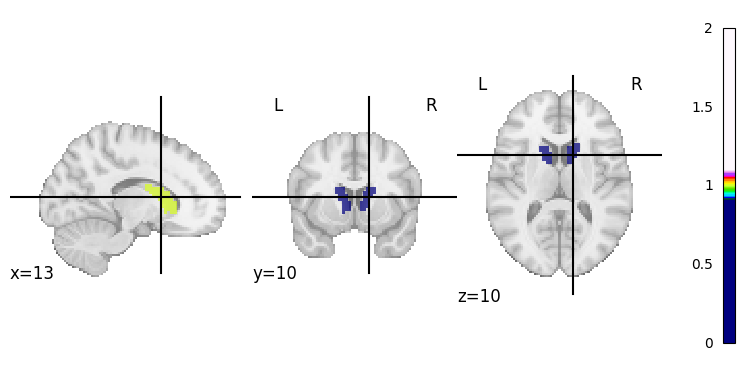

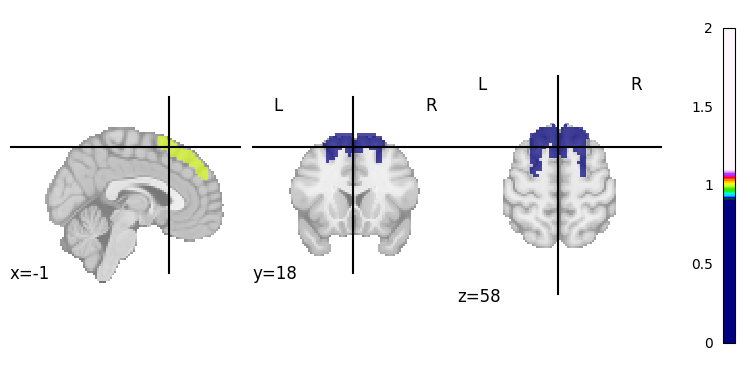

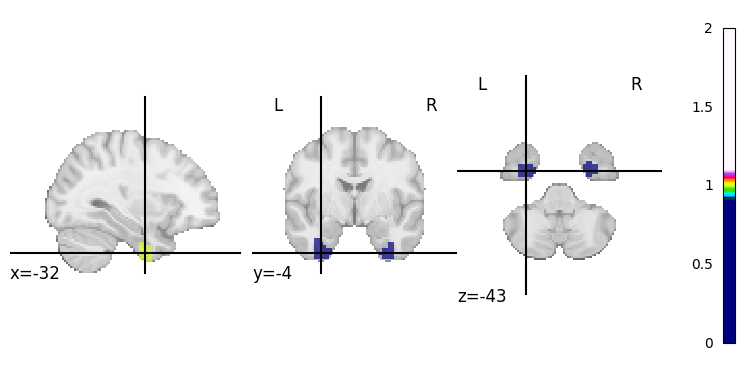

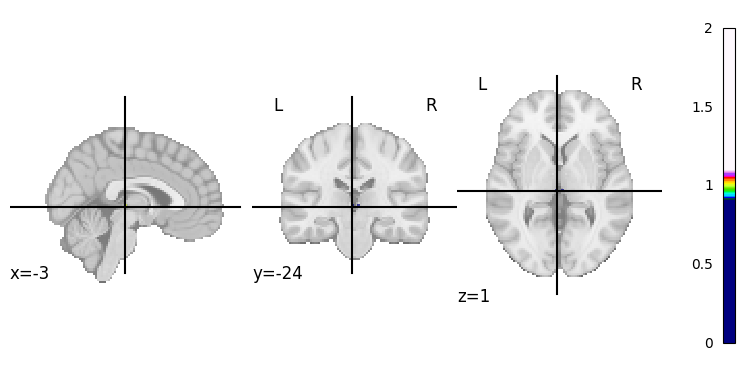

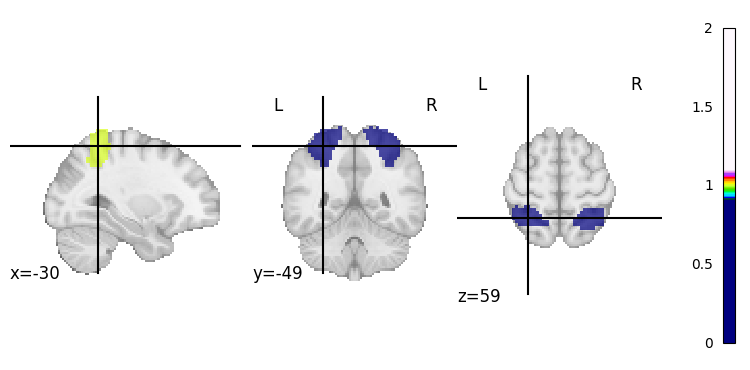

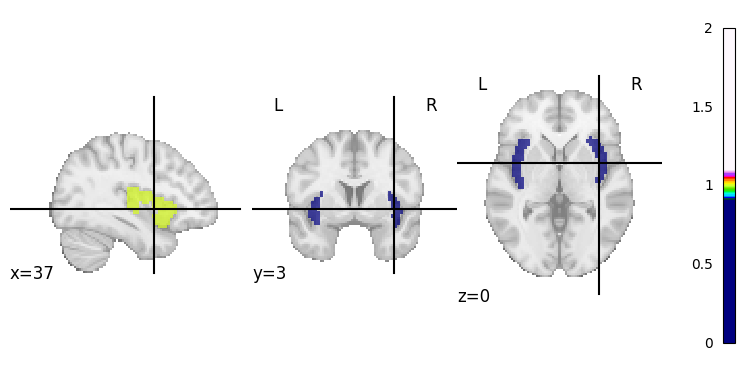

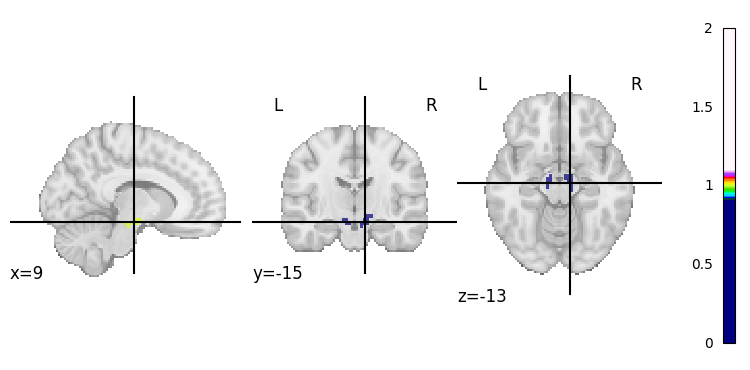

In [12]:
# plot masks to check cortical and subcortical regions
output_dir = "../../masks_MNI152NLin2009cAsym"
files = os.listdir(output_dir)[:10]
for f in files:
    print(f)
    plot_roi(os.path.join(output_dir, f))

#  Midbrain regions from probabilistic atlas

In [8]:
import os
os.environ["FSLDIR"] = "fsl"
os.environ["FSLOUTPUTTYPE"] = "NIFTI_GZ"
os.environ["PATH"] = f"{os.environ['FSLDIR']}/bin:" + os.environ["PATH"]

In [ ]:
# Lets merge SN and VTA because separately they are very small
# CIT168toMNI152-2009c_prob.nii.gz and create_mask_orig.py are from atlaskit github (Pauli probabilistic midbrain atlas 2017)

roi_labels = ["Pu", "Ca", "NAC", "EXA", "GPe", "GPi", "SNc", "RN", "SNr", "PBP", "VTA", "VeP", "HN", "HTH", "MN", "STH"]

for i, name in enumerate(roi_labels):
    print(name)
    output_file = f"{output_dir}/{name}.nii.gz"

    # No thresholding (very little 1e-10), original atlas grid 1mm - the output is binary 
    cmd = [
        "python",
        "create_mask_orig.py",
        "-i", "CIT168toMNI152-2009c_prob.nii.gz",
        "-o", output_file,
        "-t", "1e-10",
        str(i)
    ]
    subprocess.run(cmd, check=True)

    # resample to cope 3mm grid, output is probabilistic
    cmd = [
        "flirt",
        "-in", output_file,
        "-ref", reference_img_path,
        "-out", output_file,
        "-applyxfm",
        "-usesqform"
    ]
    subprocess.run(cmd, check=True)
    

    #  Binarize and apply threshold of 75%
    cmd = [
        "fslmaths",
        output_file, 
         "-thr", "0.75",
        "-bin", output_file,

    ]
    subprocess.run(cmd, check=True)

    # # check num of voxels
    # proi_img = load_img(output_file)
    # print(int(np.count_nonzero(proi_img.get_fdata())))

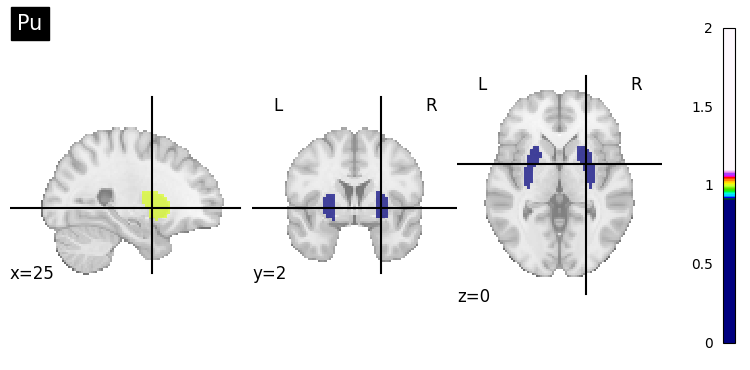

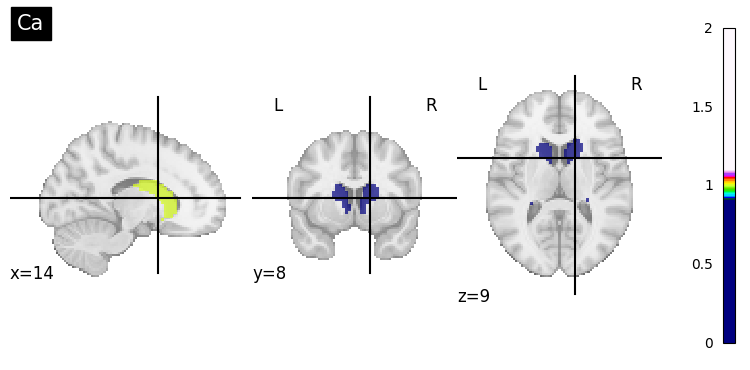

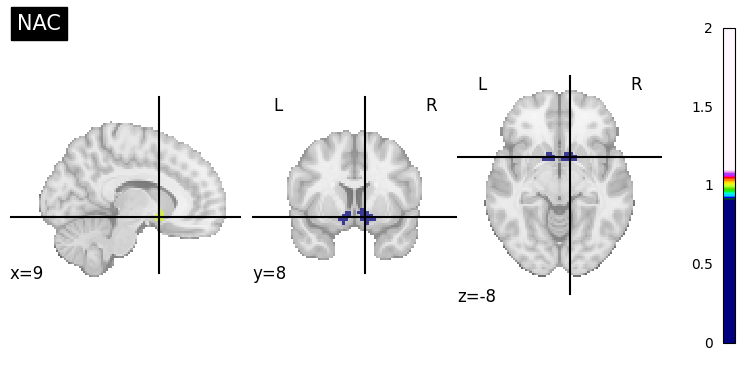

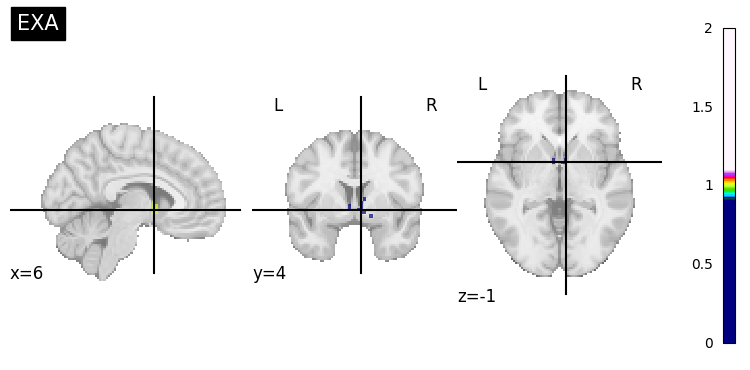

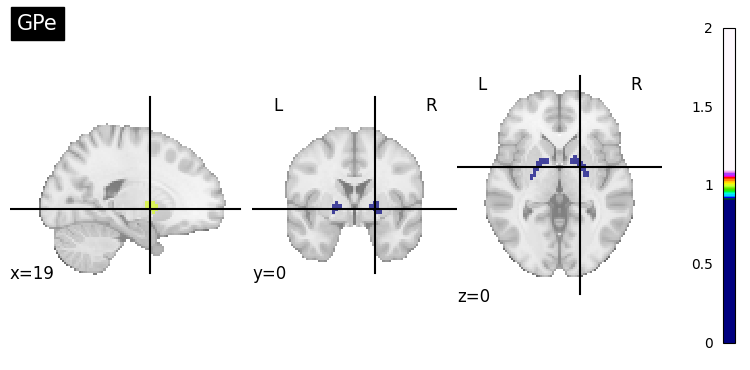

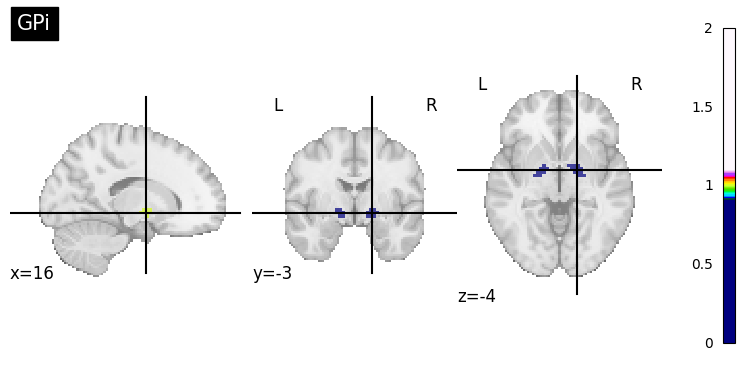

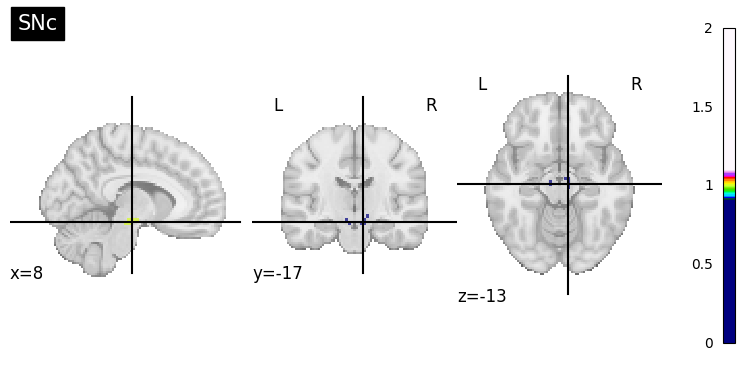

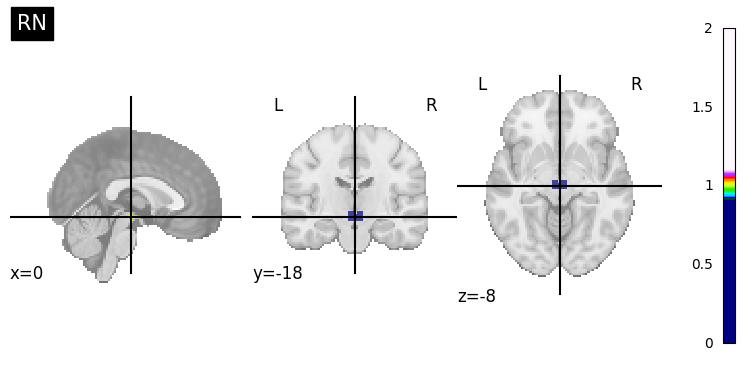

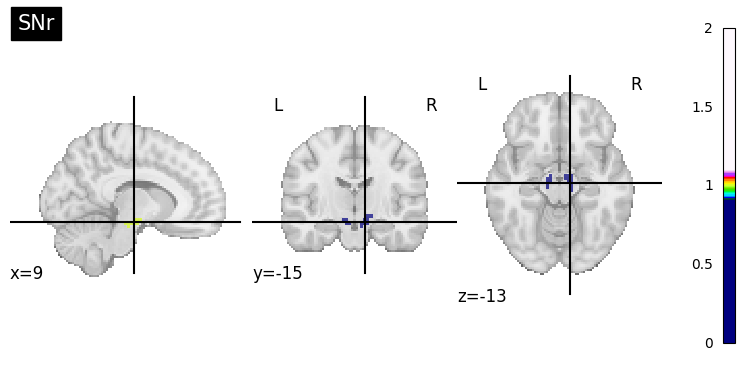

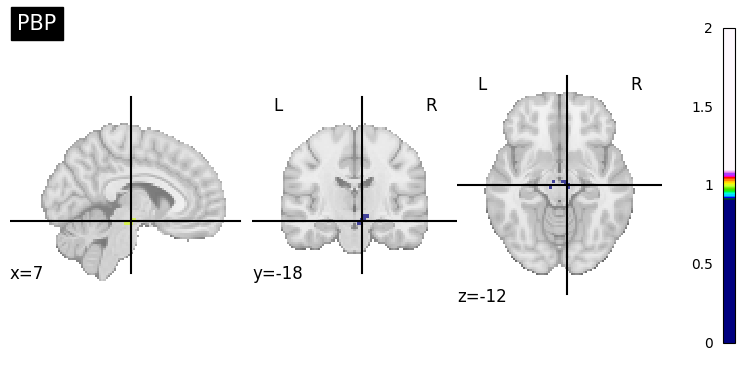

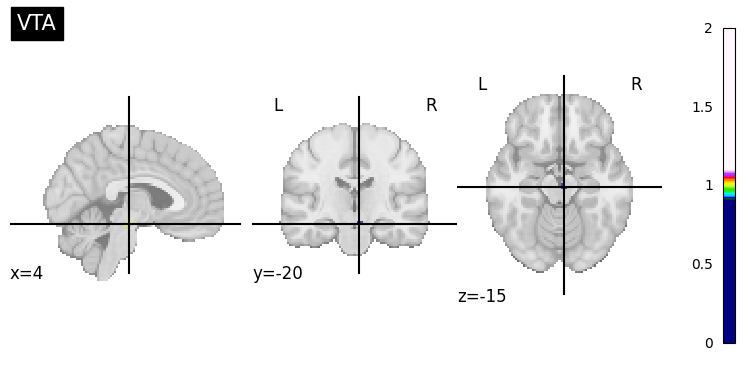

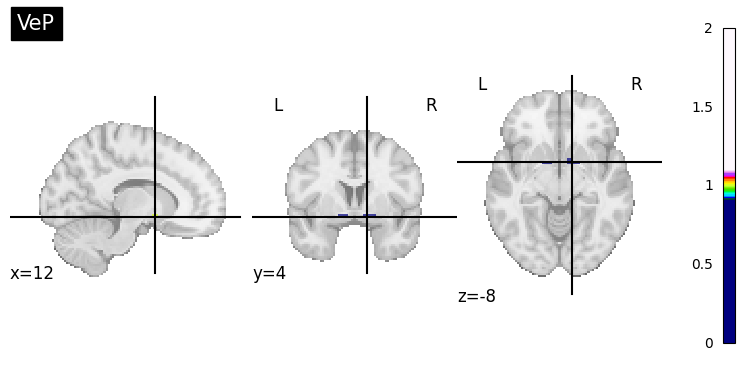

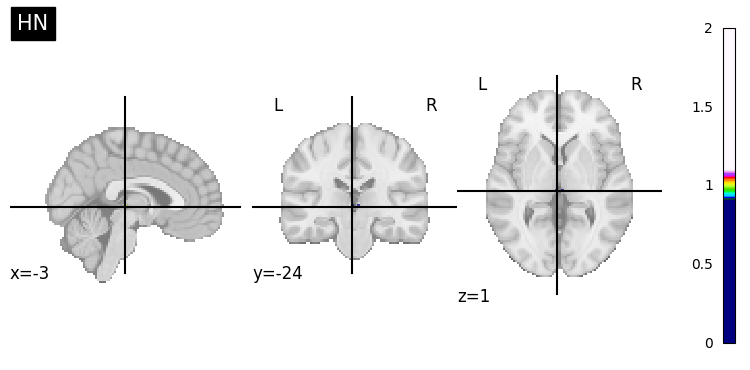

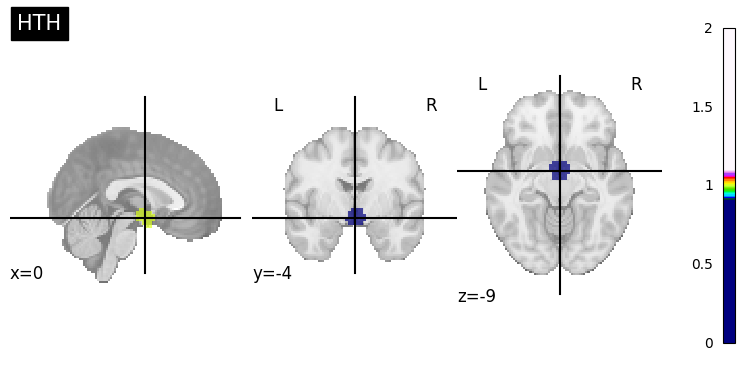

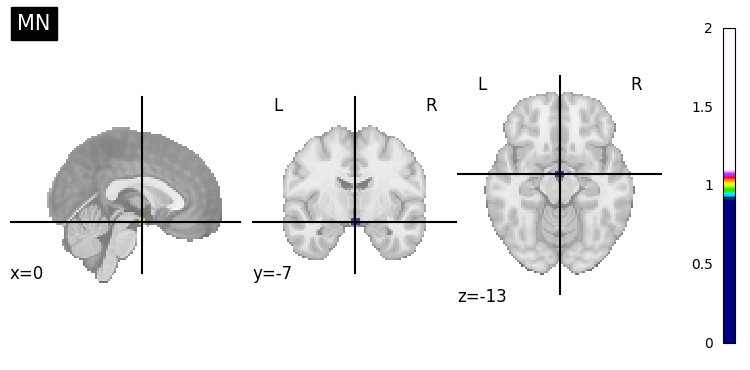

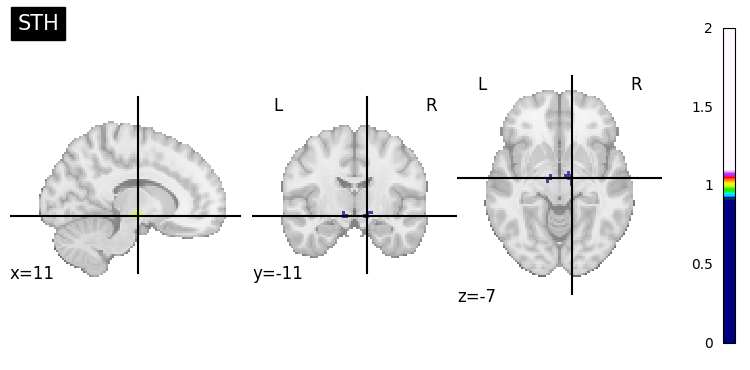

In [ ]:
roi_labels = ["Pu", "Ca", "NAC", "EXA", "GPe", "GPi", "SNc", "RN", "SNr", "PBP", "VTA", "VeP", "HN", "HTH", "MN", "STH"]

for name in roi_labels:
    output_file = f"{output_dir}/{name}.nii.gz"
    proi_img = load_img(output_file)
    plot_roi(proi_img, title=name)

In [ ]:
# Combine SNc and VTA into a single mask
# I deleted VTA and SNcmask after combining them so we would not have redundant masks
!fslmaths probing_rsa_fasting_social_isolation/masks/SNc.nii.gz -add probing_rsa_fasting_social_isolation/masks/VTA.nii.gz -bin probing_rsa_fasting_social_isolation/masks/SNc_VTA.nii.gz

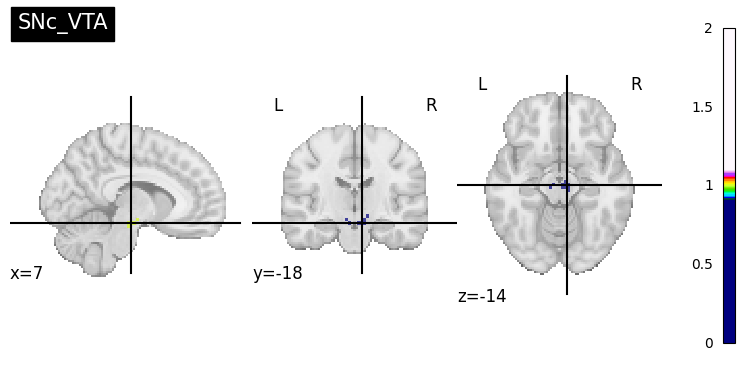

In [ ]:
plot_roi('probing_rsa_fasting_social_isolation/masks/SNc_VTA.nii.gz', title='SNc_VTA')